### Example Implementation

<function matplotlib.pyplot.show(close=None, block=None)>

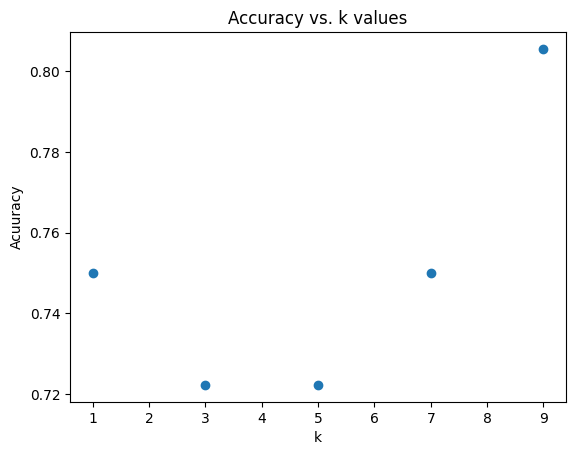

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
wine=load_wine()
X,y=wine.data,wine.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)
k_values=[1,3,5,7,9]
accuracy_scores=[]
for k in k_values:
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train,y_train)
    accuracy=knn.score(X_test,y_test)
    accuracy_scores.append(accuracy)

plt.scatter(k_values,accuracy_scores)
plt.xlabel("k")
plt.ylabel("Acuuracy")
plt.title("Accuracy vs. k values")
plt.show

In [ ]:
k_values = range(1,30)
accuracy_scores = []

for k in k_values:
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train,y_train)
    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test,y_pred)
    accuracy_scores.append(accuracy)

best_k = k_values[accuracy_scores.index(max(accuracy_scores))]
print("Best value:" ,best_k)



Best value: 9


# Import required Libraries

In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

### Loading the DATA Set

In [ ]:
wine = load_wine()
X = wine.data
y = wine.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Wine classes:", wine.target_names)

Features shape: (178, 13)
Target shape: (178,)
Wine classes: ['class_0' 'class_1' 'class_2']


### Splitting

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

### Training

In [ ]:
k_values = [1, 3, 5, 7, 9]
accuracy_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    accuracy = knn.score(X_test, y_test)
    accuracy_scores.append(accuracy)

print("K values:", k_values)
print("Accuracy scores:", accuracy_scores)

K values: [1, 3, 5, 7, 9]
Accuracy scores: [0.7777777777777778, 0.8055555555555556, 0.7222222222222222, 0.6944444444444444, 0.7222222222222222]


### Plotting

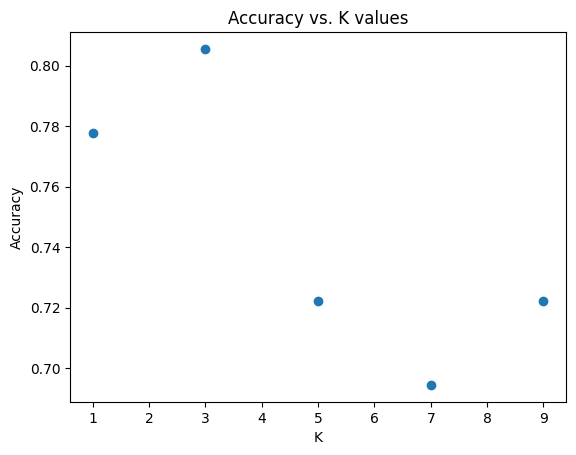

In [ ]:
plt.scatter(k_values, accuracy_scores)

plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. K values")

plt.show()

# Activity 1:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [2]:
data = pd.read_csv('creditcard.csv')
df = pd.DataFrame(data)
data

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


The 0 and 1 cases Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.1727 %


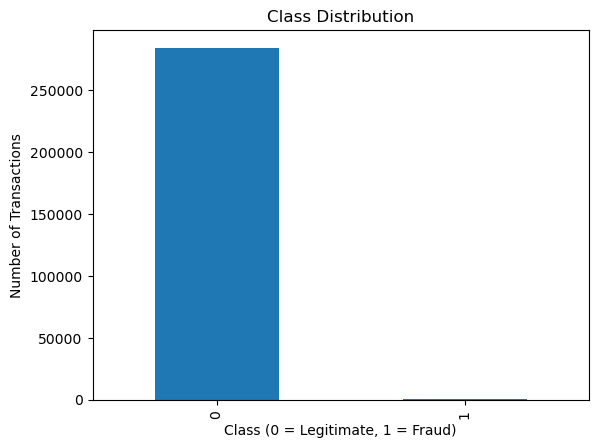

In [3]:
print("The 0 and 1 cases",df["Class"].value_counts())

print("Fraud percentage:",round((df["Class"].mean() * 100), 4),"%")

df["Class"].value_counts().plot(
    kind="bar",
    xlabel="Class (0 = Legitimate, 1 = Fraud)",
    ylabel="Number of Transactions",
    title="Class Distribution"
)

plt.show()

### Splitting Data into X and Y

In [4]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (284807, 30)
Target: (284807,)


### One Record with NAN

In [5]:
df[df['Class'].isna()]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class


In [6]:
df = df.dropna(subset=['Class'])

In [7]:
df[df['Class'].isna()]


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class


### Smote

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)  # Exact Legitimate to Fraud Ratio

In [9]:
# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Smote

In [10]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled,y_train)

In [12]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_smote, y_train_smote)

y_pred = knn.predict(X_test_scaled)

### Evaluate

In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.44      0.88      0.58        98

    accuracy                           1.00     56962
   macro avg       0.72      0.94      0.79     56962
weighted avg       1.00      1.00      1.00     56962



### GridSearchCV

In [14]:
param_grid = {
    'n_neighbors': [3, 5, 7]
}

grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=2,
    scoring='recall',
    n_jobs=-1
)

grid_search.fit(X_train_smote, y_train_smote)

print("Best k:", grid_search.best_params_)
print("Best CV Recall:", grid_search.best_score_)

Best k: {'n_neighbors': 3}
Best CV Recall: 1.0
